Name: Donovan Neal 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#Read in 'netflix_titles.csv'
titles = pd.read_csv('netflix_titles.csv')

In [3]:
#Calculate central tendency and spread for numerical fields in 'netflix_titles.csv'
titlesNumSum = titles.describe()
print(titlesNumSum)

       release_year
count   8807.000000
mean    2014.180198
std        8.819312
min     1925.000000
25%     2013.000000
50%     2017.000000
75%     2019.000000
max     2021.000000


In [4]:
#Generate summary statistics for categorical fields in 'netflix_titles.csv'
titlesObjectSum = titles.describe(include='object')
print(titlesObjectSum)

       show_id   type   title       director                cast  \
count     8807   8807    8807           6173                7982   
unique    8807      2    8804           4528                7692   
top         s1  Movie  15-Aug  Rajiv Chilaka  David Attenborough   
freq         1   6131       2             19                  19   

              country date_added rating  duration  \
count            7976       8797   8803      8804   
unique            748       1767     17       220   
top     United States   1-Jan-20  TV-MA  1 Season   
freq             2818        109   3207      1793   

                           listed_in  \
count                           8807   
unique                           514   
top     Dramas, International Movies   
freq                             362   

                                              description  
count                                                8807  
unique                                               8775  
top     Para

C:\Users\dneal\AppData\Local\Temp\ipykernel_23308\2584180268.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  titlesObjectSum = titles.describe(include='object')


###Dataset Summary

This dataset contains 8807 Netflix titles containing both movies and TV shows. 
Given the spread of the release year, the large majority of titles in this dataset
is skewed towards modern titles, mostly between the years of 2017 - 2019.

In [5]:
#Fills missing values in 'cast' collumn with 'N/A'
fillCast = titles.fillna({'cast': 'N/A'})
#Fills missing values in 'director' collumn with 'N/A'
fillDirector = titles.fillna({'director': 'N/A'})
#Fills missing values in 'country' collumn with 'N/A'
fillCountry = titles.fillna({'country': 'N/A'})
#Fills missing values in 'date_added' collumn with 'N/A'
fillDateAdded = titles.fillna({'date_added': 'N/A'})
#Fills missing values in 'rating' collumn with 'N/A'
fillRating = titles.fillna({'rating': 'N/A'})
#Fills missing values in 'duration' collumn with 'N/A'
fillDuration = titles.fillna({'duration': 'N/A'})

In [6]:
#Replaces incorrect values in 'rating' collumn with 'N/A' p.s move the incorrect values into duration since duration is emptg
titles['rating'] = titles['rating'].replace(r'^\d+.*', 'N/A', regex=True)

In [7]:
#Replaces broken text in 'director' collumn
titles['director'] = titles['director'].str.replace(r'[^a-zA-Z0-9\s:\-–&\'!?.,]', '', regex=True)
#Replaces broken text in 'cast' collumn
titles['cast'] = titles['cast'].str.replace(r'[^a-zA-Z0-9\s:\-–&\'!?.,]', '', regex=True)
#Replaces broken text in 'description' collumn
titles['description'] = titles['description'].str.replace(r'[^a-zA-Z0-9\s:\-–&\'!?.,]', '', regex=True)
#Replaces broken text in 'title' collumn
titles['title'] = titles['title'].str.replace(r'[^a-zA-Z0-9\s:\-–&\'!?.,]', '', regex=True)

In [8]:
#Strips beginning of 'country' collumn
titles['country'] = titles['country'].str.strip(',')

##Data Quality Audit and Cleaning
While analyzing the DataFrame, I discovered that there were missing values, values placed in incorrect collumns, 
values leading with incorrect characters, and broken text in multiple collumns.

To handle collumns that contained missing values, I used the pandas function '.fillna()' to fill in missing values with 'N/A'
as opposed to keeping the value in that row blank. To deal with values that were placed in the incorrect collumn, 
To handle values that were led with incorrect values, 

Finally, to handle broken text in collumns, I used a regex to filter out values in collums that contained symbols that should not be 
present in that collum, so things such as an '@' symbol in the director collumn. 

C:\Users\dneal\AppData\Local\Temp\ipykernel_23308\3990384209.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  titles['date_added'] = pd.to_datetime(titles['date_added'])


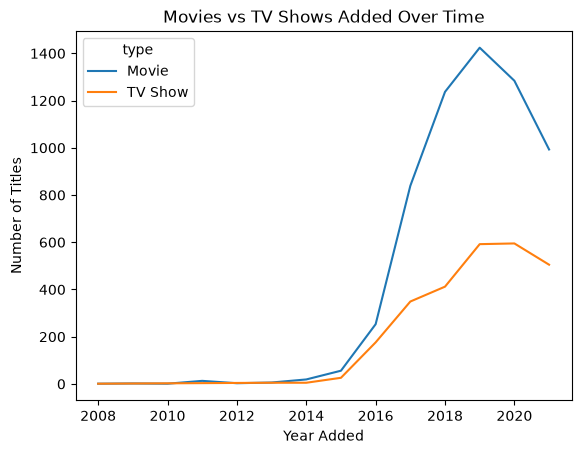

In [15]:
titles['date_added'] = pd.to_datetime(titles['date_added'])
titles['year_added'] = titles['date_added'].dt.year

counts = titles.groupby(['year_added', 'type']).size().reset_index(name='count')

sns.lineplot(data=counts, x='year_added', y='count', hue='type')
plt.title('Movies vs TV Shows Added Over Time')
plt.xlabel('Year Added')
plt.ylabel('Number of Titles')
plt.show()


From the chart, we can see that from 2008 to 2014, the movie and TV shows added to Netflix were fairly even until around 2015
when the amount of movies added to Netflix far outweighted the number of TV shows being added. Also, we can see the amount of
titles being added to Netflix rapidly grew beginning in 2015 and started to decrease beginning during 2018. 

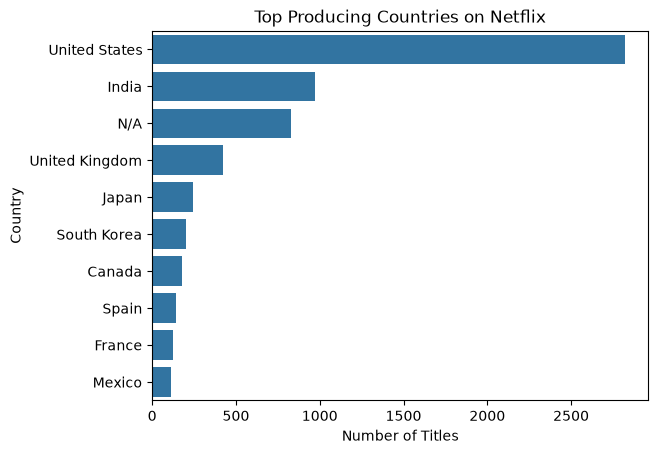

In [16]:
titles['country'] = titles['country'].fillna('N/A')

country_counts = titles['country'].value_counts().head(10).reset_index()
country_counts.columns = ['country', 'count']

sns.barplot(data=country_counts, x='count', y='country')
plt.title('Top Producing Countries on Netflix')
plt.xlabel('Number of Titles')
plt.ylabel('Country')
plt.show()

From the chart, we can see that the United States is by far the top producing country when it comes to titles
available on Netflix. Aside from that, we can that Mexico, France, Spain, Canada, South Korea, and Japan have the fewest 
amount of titles on Netflix. From this data, we can infer that titles produced in the United States tend to perform the best on Netflix. 

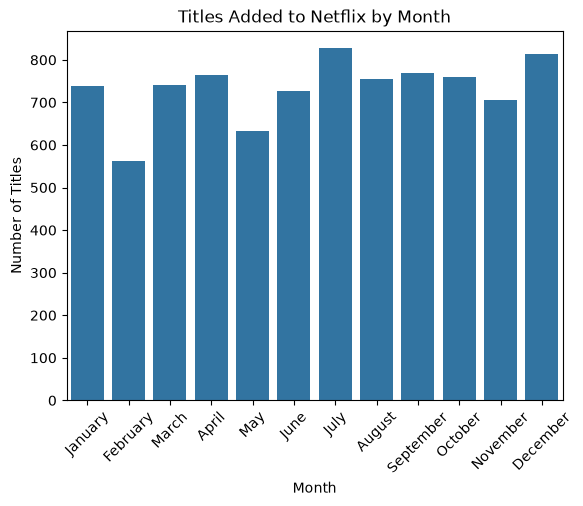

In [22]:
titles['date_added'] = pd.to_datetime(titles['date_added'])
titles['month_added'] = titles['date_added'].dt.month_name()

month_counts = titles['month_added'].value_counts().reindex(
    ['January','February','March','April','May','June',
     'July','August','September','October','November','December']
).reset_index()
month_counts.columns = ['month', 'count']

sns.barplot(data=month_counts, x='month', y='count')
plt.xticks(rotation=45)
plt.title('Titles Added to Netflix by Month')
plt.xlabel('Month')
plt.ylabel('Number of Titles')
plt.show()

Judging from the graph, there doesn't appear to be much difference in number of titles added on which months, but 
July and December are the months that have titles added more frequently, while Februrary and June are the months that recieve
the least frequent titles added.

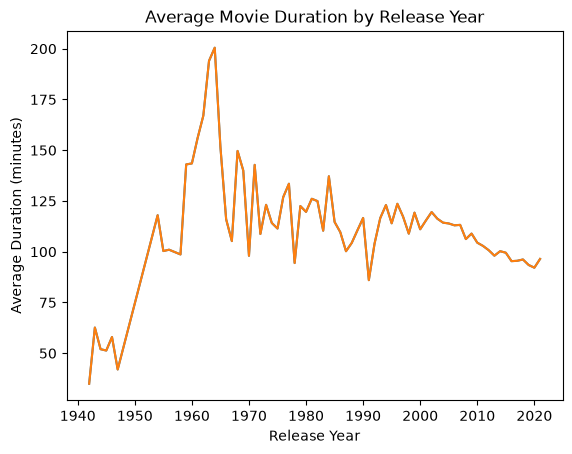

In [25]:
movies = titles[titles['type'] == 'Movie'].copy()

movies['duration_min'] = movies['duration'].str.extract('(\d+)').astype(float)

avg_duration = movies.groupby('release_year')['duration_min'].mean()

sns.lineplot(x=avg_duration.index, y=avg_duration.values)

sns.lineplot(x=avg_duration.index, y=avg_duration.values)
plt.title('Average Movie Duration by Release Year')
plt.xlabel('Release Year')
plt.ylabel('Average Duration (minutes)')
plt.show()

From the chart, we can see that over the decades, the trend of movie durations has varied greatly. From 1940 to 1950, 
movies tended to be less 70 minutes but then between 1950 and 1960, movies then grew in average duration sitting at around 110 minutes on average, and then from 1960 to 1970 movies began to peak on average to upwards of 200 minutes, but then from 1970 onwards began steadily decling in duration 
sitting anywhere 90 minutes to 130 minutes on average. From this data, we can infer that consumers prefered movies that ranged from 90 to 130 minutes as opposed to the shorter movies in the 40's and 50's and the longer movies in 70's. 

##Modeling Recommendations and Data Pitfalls

One machine learning task that I would propose to the Netflix leadership based on this data would be whether newer or older movies drive more engagemnt on Netflix. This is a classification problem as we are looking to classify movies based on engagement. The variable we are trying to predict is consumer engagment with a movie after it has been recently added to Netflix. Features from the dataset that we would include in the model would date_added and release_year especially, and then all information related to the movie so the duration and titles for example. 

Based on my exploratory data analysis, the first specific data challenge in this dataset that would complicate modeling would be the large amounts of missing data in the dataset. In order to remedy that, you would have to first figure out why the data is missing in the first place and whether it missing for valid reasons such as it not being applicable or the information not being provided, or whether the data genuinely is missing for some unknown reason. Then decide whether to drop or fill those rows with another value so it can be used for modeling. The second data challenge in the dataset is that there is a lot of broken text across the entire dataset. There are many places where there are values containg unusual symbols and text where there should not be. To fix this, you should find those values with the text and replace the ones containing this broken text so the information is able to be properly used for modeling. 

- Based on the top producing countries in Netflix, Netflix heavily favors certian markets, especially the United States when it comes to what titles get added to their platform
- Based on the Movies vs. TV shows added over time, users on Netflix seem to prefer watching more movies over TV shows based on how much more movies added to Netflix as opposed to TV shows
- Factors such as the genre, country, and duration are critical when it comes to figuring out what kind of content perfroms best on Netflix, whether it's shows or movies that have shorter durations, content that comes from a certain genre, and content that was released in a certain tome frame as examples